# Student Performance & At-Risk Prediction — EDA

This notebook performs reproducible exploratory checks on `data/processed/student_performance.csv`. It checks schema and types, missingness, exact and identifier duplicates, univariate distributions, IQR outliers, target balance, feature relationships, and potential future-information leakage. It does **not** train models or build a dashboard.

Run from the project root with `jupyter nbconvert --to notebook --execute notebooks/eda.ipynb --output eda.executed.ipynb` (or open and run all cells). Figures are written to `reports/figures/`.

The dataset is synthetic. Interpret these findings as properties of this generated sample, not as evidence about a real student population.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve paths from either the project root or this notebook's directory.
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _candidates if (p / 'data/processed/student_performance.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Could not locate data/processed/student_performance.csv from the current directory')
DATA_PATH = ROOT / 'data/processed/student_performance.csv'
FIGURE_DIR = ROOT / 'reports/figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Stable, readable figure defaults.
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_csv(DATA_PATH)
print(f'Dataset: {DATA_PATH.relative_to(ROOT)}')
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Dataset: data/processed/student_performance.csv
Shape: 1,000 rows × 7 columns


,student_id,attendance_pct,assignment_completion_pct,previous_assessment_1_pct,previous_assessment_2_pct,previous_assessment_trend_pct,at_risk
0,S00001,80.2,31.8,40.6,43.9,3.3,0
1,S00002,82.2,92.5,26.5,23.9,-2.6,0
2,S00003,57.0,65.4,22.0,27.5,5.5,0
3,S00004,75.0,45.4,64.2,64.7,0.5,0
4,S00005,89.3,78.9,45.5,62.4,16.9,0


## 1. Schema and data quality

In [2]:
print('Column types:')
display(df.dtypes.rename('dtype').to_frame())
print('Missing values by column:')
missing = df.isna().sum().rename('missing_count').to_frame()
missing['missing_pct'] = (missing['missing_count'] / len(df) * 100).round(2)
display(missing)
print(f'Exact duplicate rows: {df.duplicated().sum()}')
print(f'Duplicate student_id values: {df.student_id.duplicated().sum()}')
print(f'Unique student_id values: {df.student_id.nunique()} / {len(df)}')
print('Numeric summary:')
display(df.describe(include='all').T)

Column types:


,dtype
student_id,object
attendance_pct,float64
assignment_completion_pct,float64
previous_assessment_1_pct,float64
previous_assessment_2_pct,float64
previous_assessment_trend_pct,float64
at_risk,int64


Missing values by column:


,missing_count,missing_pct
student_id,0,0.0
attendance_pct,0,0.0
assignment_completion_pct,0,0.0
previous_assessment_1_pct,0,0.0
previous_assessment_2_pct,0,0.0
previous_assessment_trend_pct,0,0.0
at_risk,0,0.0


Exact duplicate rows: 0
Duplicate student_id values: 0
Unique student_id values: 1000 / 1000
Numeric summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,1000,1000,S00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
attendance_pct,1000.0,NaN,NaN,NaN,72.9316,15.870506,45.0,58.875,73.1,86.9,100.0
assignment_completion_pct,1000.0,NaN,NaN,NaN,64.7235,20.016264,30.0,47.275,65.45,81.025,100.0
previous_assessment_1_pct,1000.0,NaN,NaN,NaN,58.0954,21.29909,20.0,39.475,60.15,75.425,94.9
previous_assessment_2_pct,1000.0,NaN,NaN,NaN,57.8429,24.166887,0.0,38.5,58.25,77.3,100.0
previous_assessment_trend_pct,1000.0,NaN,NaN,NaN,-0.2525,11.697387,-39.8,-7.65,-0.3,7.5,38.0
at_risk,1000.0,NaN,NaN,NaN,0.091,0.287753,0.0,0.0,0.0,0.0,1.0


## 2. Feature distributions and range checks

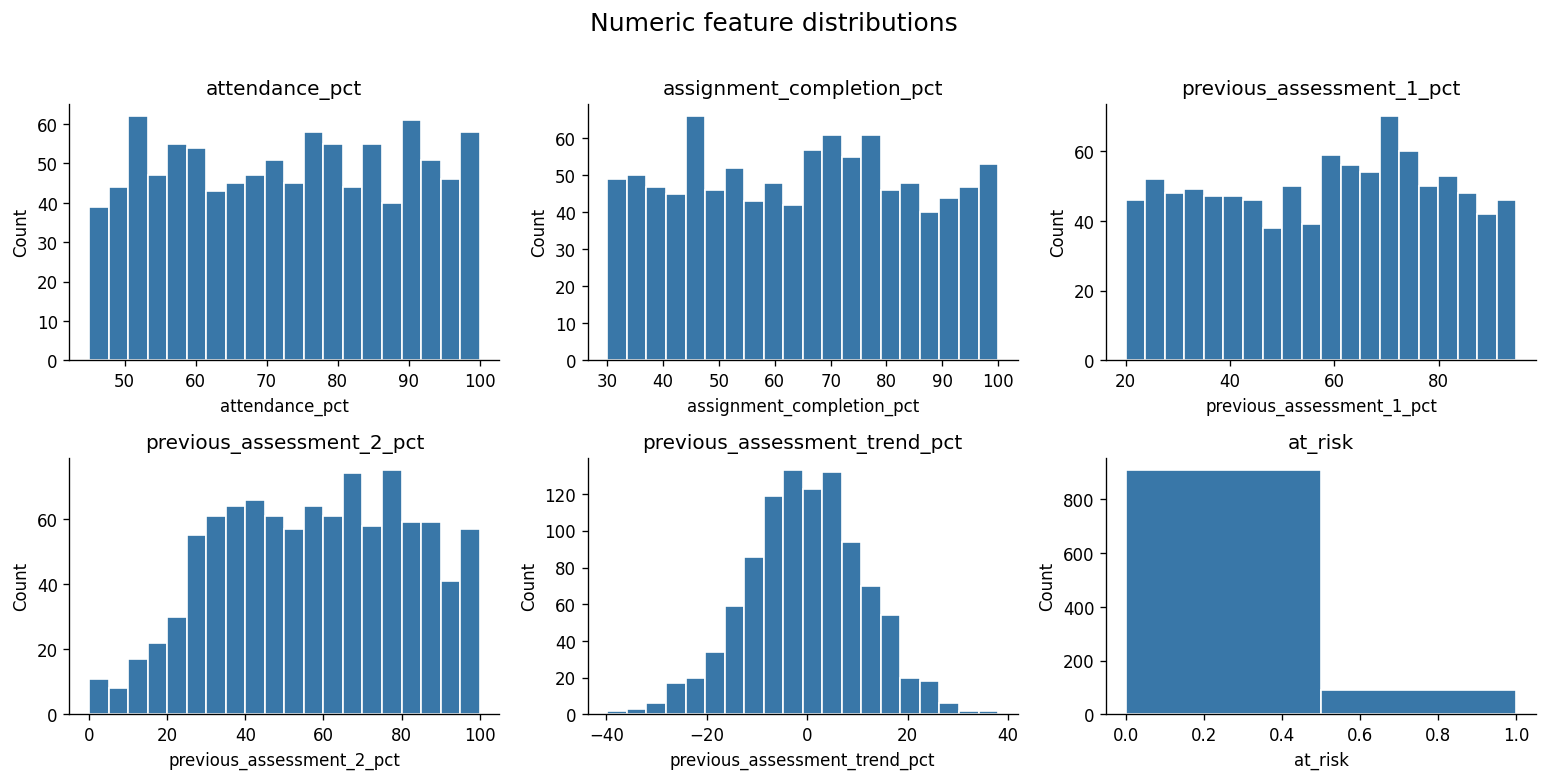

,min,max,out_of_range_count
column,,,
attendance_pct,45.0,100.0,0
assignment_completion_pct,30.0,100.0,0
previous_assessment_1_pct,20.0,94.9,0
previous_assessment_2_pct,0.0,100.0,0
previous_assessment_trend_pct,-39.8,38.0,0


Trend consistency violations (>0.11 percentage points, allowing rounding): 0


In [3]:
target = 'at_risk'
id_col = 'student_id'
feature_cols = [c for c in df.select_dtypes(include='number').columns if c != target]

# Histograms of every numeric feature (including the binary target for completeness).
plot_cols = feature_cols + [target]
ncols = 3
nrows = int(np.ceil(len(plot_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.2*nrows))
axes = np.asarray(axes).reshape(-1)
for ax, col in zip(axes, plot_cols):
    bins = 2 if col == target else 20
    ax.hist(df[col].dropna(), bins=bins, color='#3977a8', edgecolor='white')
    ax.set(title=col, xlabel=col, ylabel='Count')
for ax in axes[len(plot_cols):]: ax.remove()
fig.suptitle('Numeric feature distributions', y=1.01, fontsize=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'feature_distributions.png', bbox_inches='tight')
plt.show()

# Domain-oriented checks for bounded percentages and trend construction.
percentage_cols = ['attendance_pct', 'assignment_completion_pct', 'previous_assessment_1_pct', 'previous_assessment_2_pct']
range_rows=[]
for col in percentage_cols:
    range_rows.append({'column': col, 'min': df[col].min(), 'max': df[col].max(), 'out_of_range_count': int((~df[col].between(0,100)).sum())})
range_rows.append({'column':'previous_assessment_trend_pct','min':df.previous_assessment_trend_pct.min(),'max':df.previous_assessment_trend_pct.max(),'out_of_range_count':int((~df.previous_assessment_trend_pct.between(-100,100)).sum())})
display(pd.DataFrame(range_rows).set_index('column'))
trend_diff = (df.previous_assessment_trend_pct - (df.previous_assessment_2_pct-df.previous_assessment_1_pct)).abs()
print('Trend consistency violations (>0.11 percentage points, allowing rounding):', int((trend_diff > 0.11).sum()))

## 3. IQR outlier screening

,q1,q3,iqr,lower_fence,upper_fence,outlier_count,outlier_pct
feature,,,,,,,
attendance_pct,58.875,86.900,28.025,16.837,128.938,0,0.0
assignment_completion_pct,47.275,81.025,33.750,-3.350,131.650,0,0.0
previous_assessment_1_pct,39.475,75.425,35.950,-14.450,129.350,0,0.0
previous_assessment_2_pct,38.500,77.300,38.800,-19.700,135.500,0,0.0
previous_assessment_trend_pct,-7.650,7.500,15.150,-30.375,30.225,10,1.0


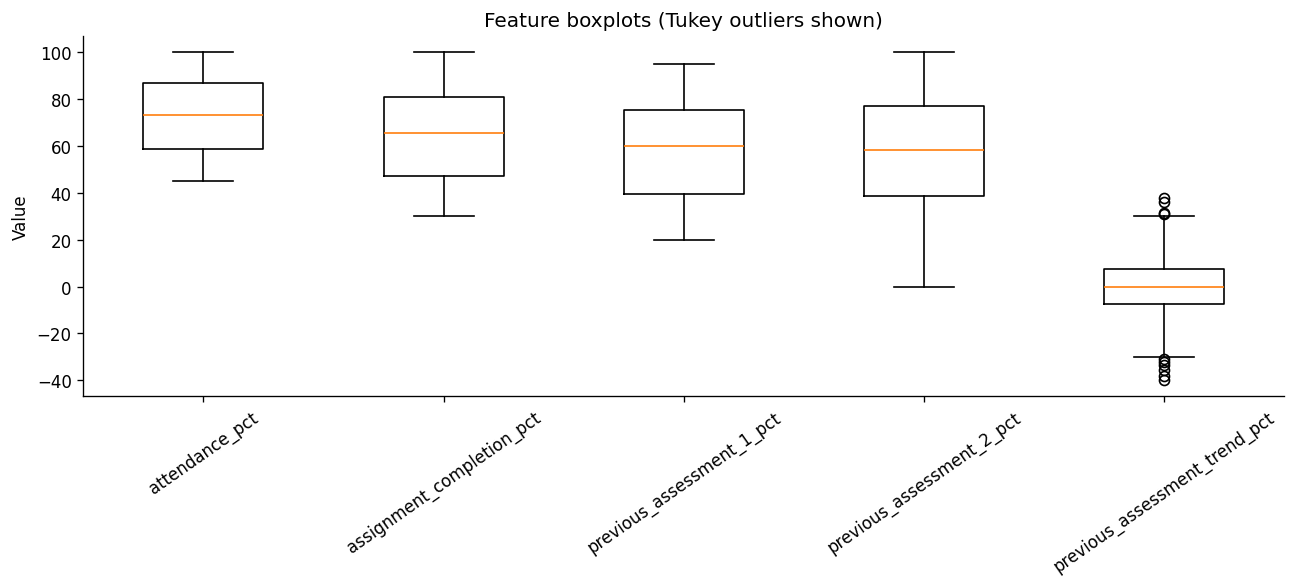

In [4]:
# Tukey 1.5×IQR screening is a flagging rule, not a deletion recommendation.
outlier_rows=[]
for col in feature_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr=q3-q1
    lo, hi=q1-1.5*iqr, q3+1.5*iqr
    mask=(df[col] < lo) | (df[col] > hi)
    outlier_rows.append({'feature':col, 'q1':q1, 'q3':q3, 'iqr':iqr, 'lower_fence':lo, 'upper_fence':hi, 'outlier_count':int(mask.sum()), 'outlier_pct':100*mask.mean()})
outliers=pd.DataFrame(outlier_rows).set_index('feature')
display(outliers.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([df[c].dropna().values for c in feature_cols], tick_labels=feature_cols, showfliers=True)
ax.set(title='Feature boxplots (Tukey outliers shown)', ylabel='Value')
ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'feature_boxplots.png', bbox_inches='tight')
plt.show()

## 4. At-risk class balance

,count,percent
at_risk,,
0,909,90.9
1,91,9.1


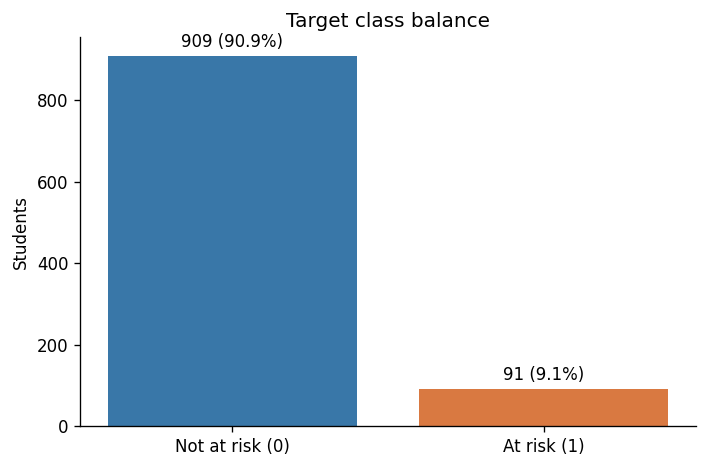

In [5]:
class_counts=df[target].value_counts().sort_index()
class_pct=(class_counts/len(df)*100).round(2)
display(pd.DataFrame({'count':class_counts, 'percent':class_pct}))
fig, ax = plt.subplots(figsize=(6,4))
labels=[f'Not at risk (0)', f'At risk (1)']
values=[int(class_counts.get(0,0)), int(class_counts.get(1,0))]
bars=ax.bar(labels, values, color=['#3977a8','#d97941'])
ax.set(title='Target class balance', ylabel='Students')
ax.bar_label(bars, labels=[f'{v} ({v/len(df):.1%})' for v in values], padding=3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'class_balance.png', bbox_inches='tight')
plt.show()

## 5. Feature relationships

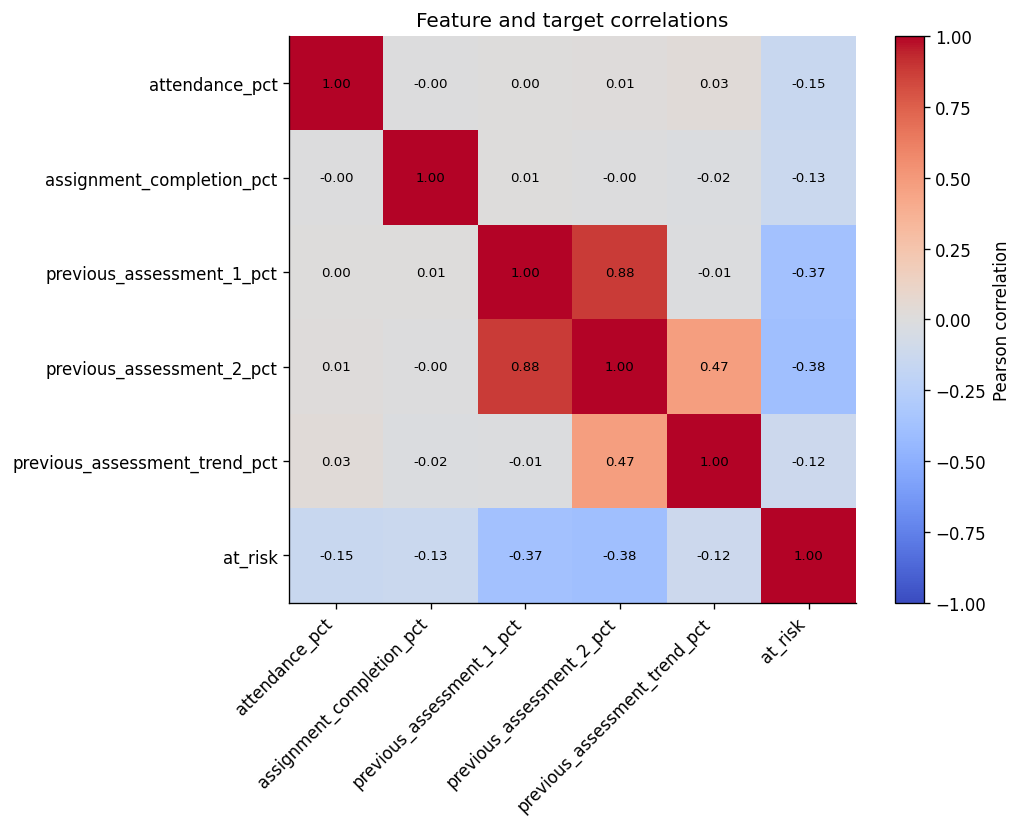

Pearson correlation with at_risk (descriptive only):


,correlation
previous_assessment_2_pct,-0.383842
previous_assessment_1_pct,-0.367642
attendance_pct,-0.145363
assignment_completion_pct,-0.132350
previous_assessment_trend_pct,-0.123602


In [6]:
corr=df[feature_cols+[target]].corr(numeric_only=True)
fig, ax=plt.subplots(figsize=(9,7))
image=ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr.index)), labels=corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8,color='black')
fig.colorbar(image, ax=ax, label='Pearson correlation')
ax.set_title('Feature and target correlations')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'correlation_heatmap.png', bbox_inches='tight')
plt.show()
print('Pearson correlation with at_risk (descriptive only):')
display(corr[target].drop(target).sort_values().rename('correlation').to_frame())

## 6. Future-information leakage review

In [7]:
# Empirical schema review: identify columns that look like post-outcome or target-derived fields.
leakage_terms=('next','future','final','outcome','label','risk_score','predicted')
possible_leakage=[c for c in df.columns if c != target and any(term in c.lower() for term in leakage_terms)]
print('Columns with potentially post-outcome names:', possible_leakage)
print('Target column:', target)
print('Identifier candidate:', id_col, '| unique:', df[id_col].is_unique)
print('Feature columns:', feature_cols)
print('Target-derived check: at_risk is binary; there is no next-assessment score column in the CSV.')

Columns with potentially post-outcome names: []
Target column: at_risk
Identifier candidate: student_id | unique: True
Feature columns: ['attendance_pct', 'assignment_completion_pct', 'previous_assessment_1_pct', 'previous_assessment_2_pct', 'previous_assessment_trend_pct']
Target-derived check: at_risk is binary; there is no next-assessment score column in the CSV.


### Leakage conclusion

The CSV contains no field with an obvious future/outcome name, and the generator source (`src/data/generate_data.py`) specifies that attendance, assignment completion, and the two prior assessments are generated as pre-next-assessment inputs. `previous_assessment_trend_pct` is computed from those two prior assessment scores. The future `next_score` is used only to create `at_risk` and is not retained. On the documented synthetic data-generation timeline, no future-information predictor is present. `student_id` is an identifier and should be excluded from any future predictive feature set. For a real dataset, verify timestamps and collection procedures with its data owner; column names alone cannot establish chronology.

## 7. Compact findings summary

In [8]:
print(f'Rows/columns: {len(df)} / {len(df.columns)}')
print(f'Missing cells: {int(df.isna().sum().sum())}')
print(f'Exact duplicate rows: {int(df.duplicated().sum())}')
print(f'Duplicate IDs: {int(df.student_id.duplicated().sum())}')
print(f'At-risk prevalence: {df.at_risk.mean():.1%} ({int(df.at_risk.sum())} of {len(df)})')
print('IQR outliers by feature:')
print(outliers['outlier_count'].to_string())
print(f'Figures saved under: {FIGURE_DIR.relative_to(ROOT)}')

Rows/columns: 1000 / 7
Missing cells: 0
Exact duplicate rows: 0
Duplicate IDs: 0
At-risk prevalence: 9.1% (91 of 1000)
IQR outliers by feature:
feature
attendance_pct                    0
assignment_completion_pct         0
previous_assessment_1_pct         0
previous_assessment_2_pct         0
previous_assessment_trend_pct    10
Figures saved under: reports/figures
